In [23]:
import pandas as pd

# Load the dataset (adjust file path accordingly)
df = pd.read_csv('Online retail.csv')

# Split the single column into individual items
df['Items'] = df.iloc[:, 0].str.split(',')

# Create a list of transactions
transactions = df['Items'].tolist()

# Create a binary matrix for the Apriori algorithm
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_ary, columns=te.columns_)

# Display the transaction matrix (binary matrix)
print(basket.head())

    asparagus  almonds  antioxydant juice  asparagus  avocado  babies food  \
0       False    False              False      False    False        False   
1       False    False              False      False    False        False   
2       False    False              False      False     True        False   
3       False    False              False      False    False        False   
4       False    False              False      False    False        False   

   bacon  barbecue sauce  black tea  blueberries  ...  turkey  vegetables mix  \
0  False           False      False        False  ...   False           False   
1  False           False      False        False  ...   False           False   
2  False           False      False        False  ...    True           False   
3  False           False      False        False  ...   False           False   
4  False           False      False        False  ...   False           False   

   water spray  white wine  whole weat flour

In [24]:
from mlxtend.frequent_patterns import apriori, association_rules

# Apply apriori algorithm with a minimum support threshold
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)

# Generate the association rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

# Display the rules
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

                   antecedents                 consequents   support  \
0              (mineral water)                   (avocado)  0.011467   
1                    (avocado)             (mineral water)  0.011467   
2                    (burgers)                      (cake)  0.011467   
3                       (cake)                   (burgers)  0.011467   
4                    (burgers)                 (chocolate)  0.017067   
..                         ...                         ...       ...   
403  (mineral water, pancakes)                 (spaghetti)  0.011467   
404      (spaghetti, pancakes)             (mineral water)  0.011467   
405            (mineral water)       (spaghetti, pancakes)  0.011467   
406                (spaghetti)   (mineral water, pancakes)  0.011467   
407                 (pancakes)  (mineral water, spaghetti)  0.011467   

     confidence      lift  
0      0.048125  1.449559  
1      0.345382  1.449559  
2      0.131498  1.622103  
3      0.141447  1.6221

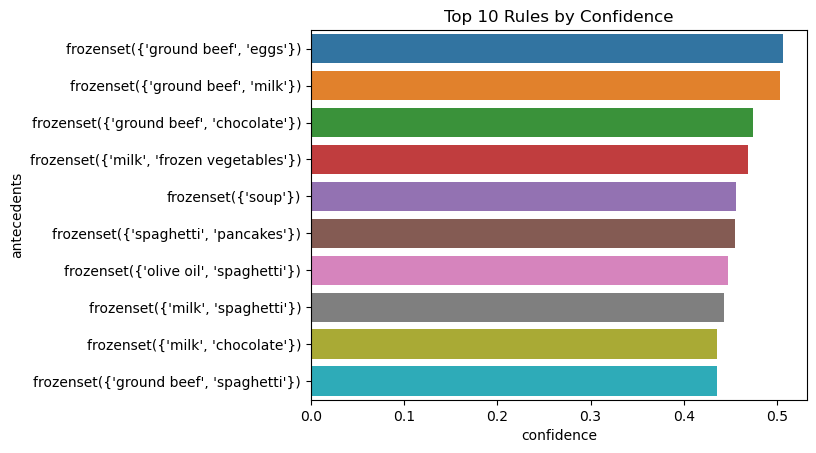

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore',category= DeprecationWarning)
# Plotting top 10 rules based on confidence
top_10_rules = rules.nlargest(10, 'confidence')
sns.barplot(x='confidence', y='antecedents', data=top_10_rules)
plt.title('Top 10 Rules by Confidence')
plt.show()

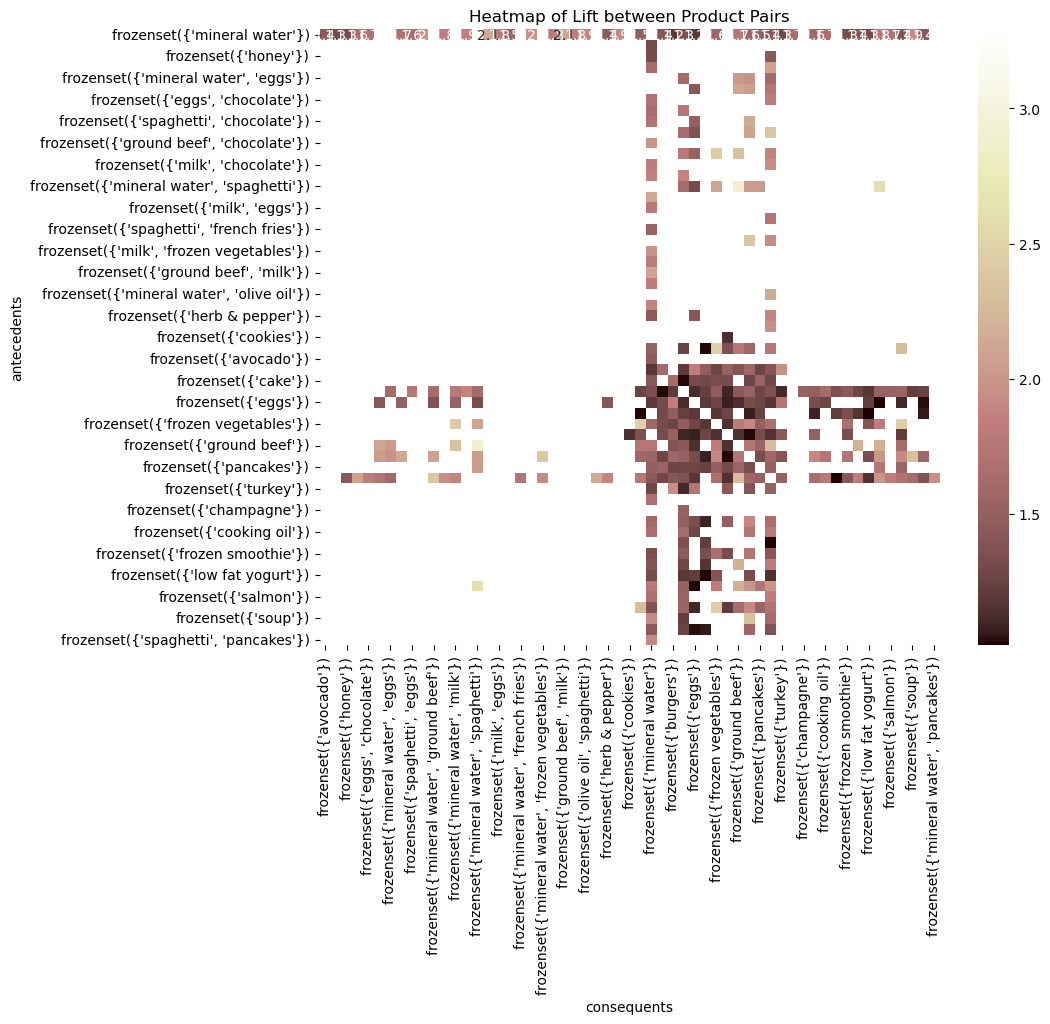

In [31]:
warnings.simplefilter(action='ignore',category= FutureWarning)
# Create a matrix of antecedents and consequents by lift
lift_matrix = rules.pivot(index='antecedents', columns='consequents', values='lift')
# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(lift_matrix, annot=True, cmap='pink')
plt.title('Heatmap of Lift between Product Pairs')
plt.show()

In [ ]:
#4. Interview Questions:
#Q1. What is Lift and why is it important in Association Rules?
#ift is the ratio of the observed support of an itemset to the expected support if the itemsets were independent.
#Mathematically, Lift = Confidence / Expected Confidence.
#Importance: It helps to measure whether the occurrence of one item increases the likelihood of the other. If Lift > 1, it implies a strong association between

In [ ]:
#Q2. What are Support and Confidence? How do you calculate them?
#Support is the fraction of transactions that contain a particular itemset.
#Formula: Support(X) = (Number of transactions containing X) / (Total transactions)
#Confidence is the probability that a transaction containing itemset A also contains itemset B.
#Formula: Confidence(A → B) = Support(A ∪ B) / Support(A)

In [ ]:
#Q3. What are some limitations or challenges of Association Rule Mining?
#Challenges:
#Scalability: Apriori can be computationally expensive on large datasets because it generates a large number of candidate itemsets.
#Choosing thresholds: Setting appropriate support, confidence, and lift thresholds is critical. Too high, and you might miss interesting rules; too low, and you get too many rules.
#Data sparsity: Many real-world datasets have sparse transactions, which makes it harder to find meaningful associations.
#Interpretability: Large numbers of rules may be hard to interpret or act upon, so filtering for interesting rules is necessary.